# Plotting Analysis for Post-Processing

Ted Balabanski

In [1]:
# plotting analysis for the lid-driven cavity solver (post-processing)
# dependencies
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import FuncFormatter
import re
import sys
import os

# import the plotting utils
from plot import *

# set a color theme for the plots
colors = ["#861F41", "#E5751F", "#642667", "#2A4D14", "#CE0058", "#508590", "#2CD5C4"]

In [11]:
# get the basepath of data
basepath = r"../data/"
datapaths = [name for name in os.listdir(basepath) if os.path.isdir(os.path.join(basepath, name))]

# iterate through each folder in the data file
# and read it in as a parameter, to build a dataframe
paramlist = []
for path in datapaths:
    # read in the parameters
    datafile = os.path.join(basepath, path, "parameters.dat")
    params = read_parameters(datafile)

    # add the filename into it and add it to the dict
    params['file'] = path
    paramlist.append(params)

# build a pandas df of the params of each run
paramdf = pd.DataFrame(paramlist)
print(paramdf.shape)
paramdf.head(5)

(19, 10)


,imms,isgs,imax,jmax,cfl,re,kappa,cx,cy,file
0,0,1,129,129,0.9,100.0,0.10,0.010000,0.010000,nf_129_sgs
1,0,0,33,33,0.9,100.0,0.01,0.010000,0.010000,nf_33_pj
2,1,1,33,33,0.9,100.0,0.10,0.007812,0.007812,mms_65_sgs_c0078
3,0,1,33,33,0.9,100.0,0.01,0.010000,0.010000,nf_33_sgs
4,0,1,259,259,0.8,500.0,0.10,0.010000,0.010000,nf_259_sgs_re500


For each of the items below, I've copied the instructions from the project description for my personal reference.

## Instruction item 1. Residual history

Residual history for conservation of mass, x-momentum, and y-momentum:
* Residual comparison between different relaxation methods (PJ, SGS)
* Residual comparison among different mesh sizes (at least two, e.g., 65x65 and 129x129)

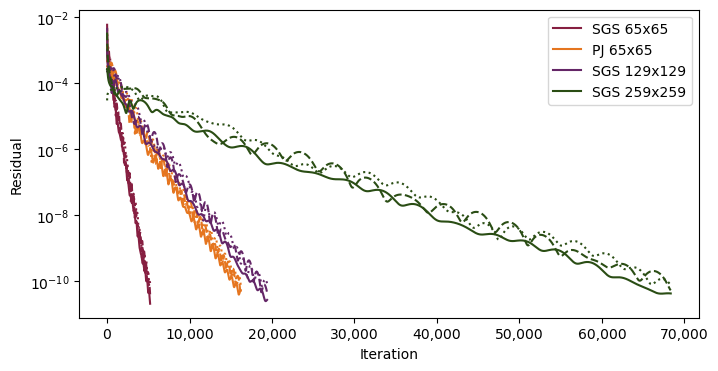

In [5]:
# pull out the 
CFL, RE, KAPPA, CX = 0.9, 100, 0.1, 0.01
plt1df = paramdf[(paramdf.imms == 0) & #(paramdf.cfl == CFL) & #(paramdf.imax == 65) &
    (paramdf.re == RE) & (paramdf.kappa == KAPPA) & (paramdf.cx == CX)]
plt1df = plt1df.sort_values(by='imax', ascending=True)

# iterate through each 
fig, ax = plt.subplots(1, 1, figsize=(8,4))

# iterate through each file
for i, file in enumerate(plt1df.file.values):
    # read the consumption history
    hist = read_convergence_history(os.path.join(basepath, file, "history.dat"))

    # plot the history
    label = "SGS" if plt1df.iloc[i, 1] == 1 else "PJ"
    label += " " + str(plt1df.iloc[i,2]) + "x" + str(plt1df.iloc[i,3])
    ax.plot(hist.iteration[1:], hist.resp[1:], linestyle="solid", color=colors[i], label=label)
    ax.plot(hist.iteration[1:], hist.resu[1:], linestyle="dashed", color=colors[i])
    ax.plot(hist.iteration[1:], hist.resv[1:], linestyle="dotted", color=colors[i])

# format the axes
ax.set_xlabel("Iteration")
ax.set_ylabel("Residual")
ax.set_yscale('log')
ax.legend()
ax.get_xaxis().set_major_formatter(FuncFormatter(lambda x, p: "{:,.0f}".format(x)))

plt.savefig("../figs/residual-history-comparison.png", dpi=600, bbox_inches='tight')
plt.show()    

## Instruction item 2. Comparison MMS solution

Comparison of MMS solutions and your solutions of u at a reasonable size mesh.

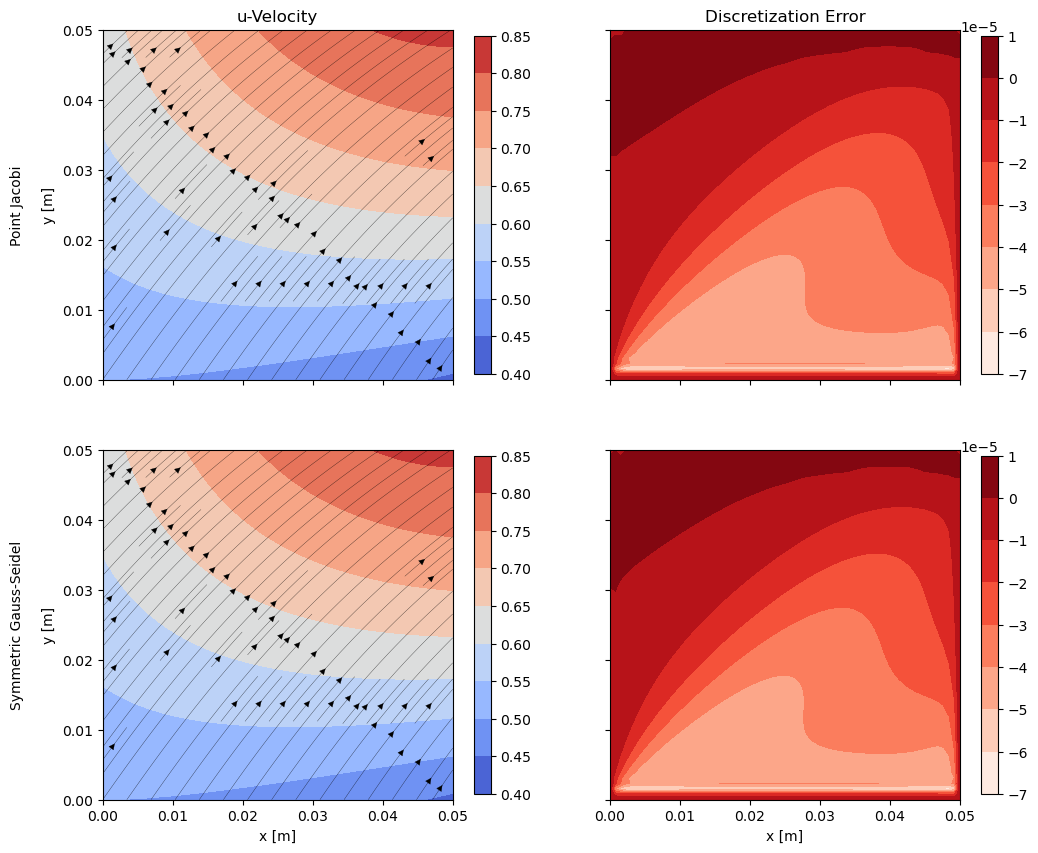

In [12]:
# set the parameters and get the df of mms dataframe
CFL, RE, KAPPA, CX = 0.9, 100, 0.1, 0.01
plt2df = paramdf[(paramdf.imms == 1) & (paramdf.cfl == CFL) &
    (paramdf.re == RE) & (paramdf.kappa == KAPPA) & (paramdf.cx == CX)]
n = plt2df.shape[0]

# initialize the plot
fig, axes = plt.subplots(n, 2, figsize=(n*6, 10), sharex=True, sharey=True)
axf = axes.flatten()

# iterate through each of the solutions
for i, file in enumerate(plt2df.file.values):
    # read in the data
    res = read_solution(os.path.join(basepath, file, "cavity.dat"))
    nx, ny = read_soln_size(os.path.join(basepath, file, "cavity.dat"))

    # make a meshgrid of the x and y values
    x = res.x.values.reshape((nx, ny))[:,0].T
    y = res.y.values.reshape((nx, ny))[0,:].T
    x, y = np.meshgrid(x, y, indexing='xy')
    u = res.u.values.reshape((nx, ny))
    v = res.v.values.reshape((nx, ny))
    deu = res.deu.values.reshape((nx, ny))
        
    # plot the plot
    ax1, ax2 = axes[i, 0], axes[i, 1]
    im1 = ax1.contourf(x, y, u, cmap='coolwarm')
    im2 = ax2.contourf(x, y, deu, cmap='Reds')

    # plot streamlines (if applicable)
    ax1.streamplot(x, y, u, v, color='k', linewidth=0.2)

    # format the plot
    simtype = "Symmetric Gauss-Seidel\n\n" if plt2df.iloc[i, 1] == 1 else "Point Jacobi\n\n"
    ax1.set_ylabel(simtype + "y [m]")
    ax1.set_aspect(ny/nx)
    ax2.set_aspect(ny/nx)
    plt.colorbar(im1, ax=ax1, fraction=0.04)
    plt.colorbar(im2, ax=ax2, fraction=0.04)
    
# format the axes
axes[0, 0].set_title("u-Velocity")
axes[0, 1].set_title("Discretization Error")
axes[1, 0].set_xlabel("x [m]")
axes[1, 1].set_xlabel("x [m]")    

plt.savefig("../figs/mms-solution-validation.png", dpi=600, bbox_inches='tight')
plt.show()

## Instruction item 3. DE and Order of Accuracy

Plots of norm of DE (log-log scale) and observed or accuracy $\hat{p}$ (semilogx scale) versus a representative node spacing (e.g., $\sqrt{n_x \times n_y}$ for the MMS case.

/tmp/ipykernel_987332/873743314.py:28: RuntimeWarning: divide by zero encountered in log
  phat = (1/np.log(r)) * np.log((pprev - pctr) / (pctr - panalytical)) # order of accuracy


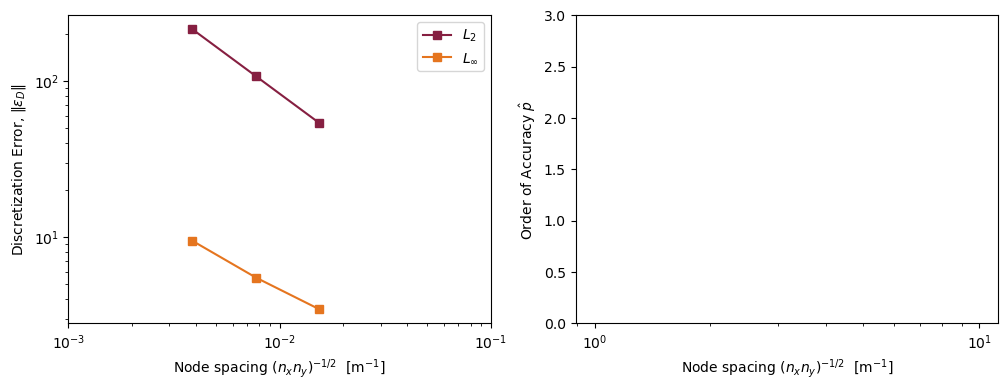

In [14]:
# read each non-mms solution with the same parameters
CFL, RE, KAPPA, CX = 0.9, 100, 0.1, 0.01
plt3df = paramdf[(paramdf.imms == 0) & (paramdf.cfl == CFL) & (paramdf.isgs == 1) &
    (paramdf.re == RE) & (paramdf.kappa == KAPPA) & (paramdf.cx == CX)]
plt3df = plt3df.sort_values(by='imax', ascending=True)

# initialize the plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# initialize the arrays for results
spacing = []
del2 = []
deinf = []
phats = []

# iterate through each of the rows
panalytical = 0.801333844662
for i, file in enumerate(plt3df.file.values):
    # read in the data
    res = read_solution(os.path.join(basepath, file, "cavity.dat"))
    p = res.p.values
    nx, ny = read_soln_size(os.path.join(basepath, file, "cavity.dat"))

    # calculate the observed order of accuracy
    pctr = p[p.size // 2] # center of the array
    if i > 0:
        r = nx / nxprev # refinement factor
        phat = (1/np.log(r)) * np.log((pprev - pctr) / (pctr - panalytical)) # order of accuracy
        phats.append(phat)

    # reset for the next iteration
    nxprev = nx
    pprev = pctr

    # calculate the L2 and Linfinity norm of the DE
    del2.append(np.linalg.norm(p))
    deinf.append(np.max(p))
    spacing.append(1/np.sqrt(nx * ny))

# generate the plots
ax1.plot(spacing, del2, color=colors[0], marker='s', label=r"$L_2$")
ax1.plot(spacing, deinf, color=colors[1], marker='s', label=r"$L_\infty$")
ax2.plot(spacing[1:], phats, color=colors[0], marker='s')

# format the plot
ax1.set_xscale('log')
ax1.set_xlim(1e-3, 1e-1)
ax1.set_yscale('log')
ax1.set_xlabel(r"Node spacing $(n_x n_y)^{-1/2}$  [m$^{-1}$]")
ax1.set_ylabel(r"Discretization Error, $\| \epsilon_D \|$")
ax1.legend()

ax2.set_xscale('log')
ax2.set_xlabel(r"Node spacing $(n_x n_y)^{-1/2}$  [m$^{-1}$]")
ax2.set_ylabel(r"Order of Accuracy $\hat{p}$")
ax2.set_ylim(0, 3)

# save and show the plot
plt.savefig("../figs/error-validation.png", dpi=600, bbox_inches='tight')
plt.show()

## Instruction item 4. Plot of the solution

Contours of solutions of p, u, and v (including streamlines for u) at Re = 100.

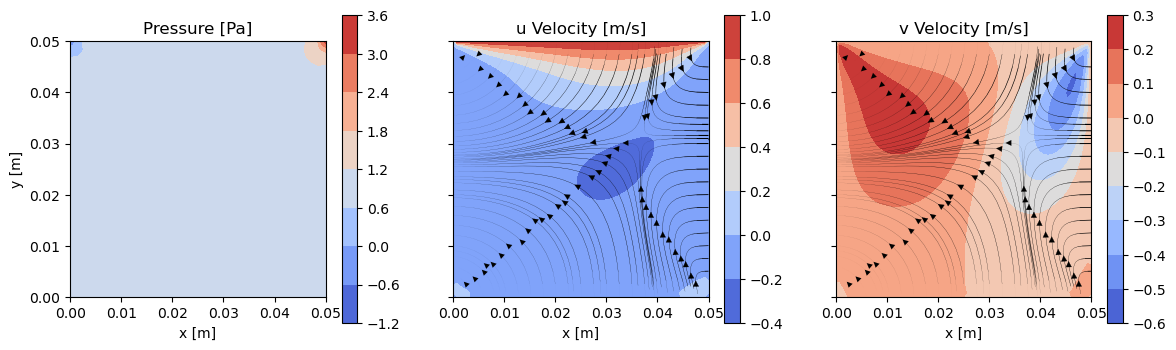

In [15]:
# read and plot the results
resultsfile = os.path.join(basepath, "nf_65_sgs", "cavity.dat")
res = read_solution(resultsfile)
nx, ny = read_soln_size(resultsfile)
plot_solution(res, nx, ny, savefile="../figs/results-re100")

## Instruction item 6. DE and Richardson Extrapolation

Estimate of discretization error or discretization uncertainty using Richardson
extrapolation (x-y plot of u velocity for a vertical line through the center of the channel).

## Instruction item 7. Effects of Reynolds Number on u-velocity

Effects of Re via contour plot of u and streamlines for your choice of mesh resolution

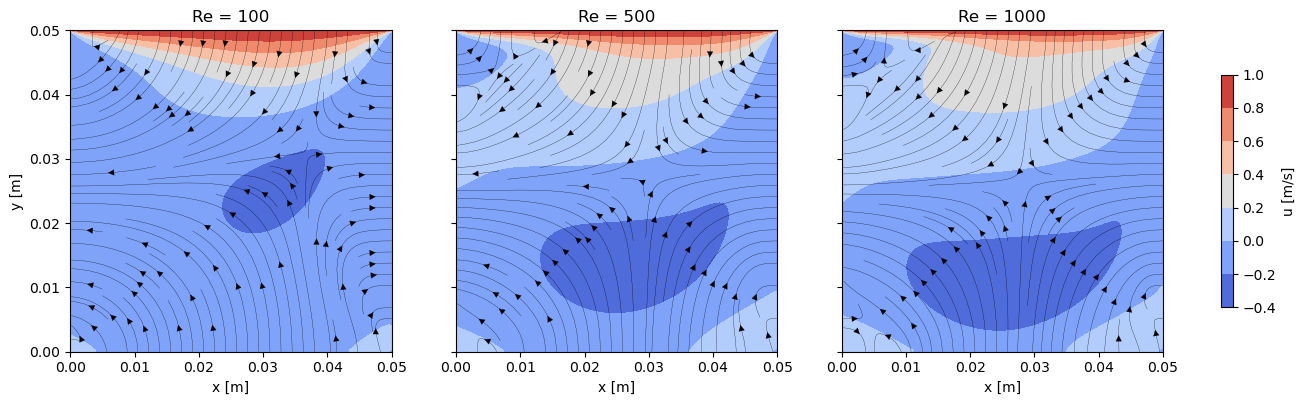

In [19]:
# set the parameters and get the df of mms dataframe
IMAX, KAPPA, CX = 259, 0.1, 0.01
plt7df = paramdf[(paramdf.imms == 0) &
    (paramdf.imax == IMAX) & (paramdf.kappa == KAPPA) & (paramdf.cx == CX)]
plt7df = plt7df.sort_values(by="re", ascending=True)
n = plt7df.shape[0]

# initialize the plot
fig, axes = plt.subplots(1, n, figsize=(5*n, 5), sharey=True)
axf = axes.flatten()

# iterate through each of the solutions
for i, file in enumerate(plt7df.file.values):
    # read in the data
    res = read_solution(os.path.join(basepath, file, "cavity.dat"))
    nx, ny = read_soln_size(os.path.join(basepath, file, "cavity.dat"))

    # make a meshgrid of the x and y values
    x = res.x.values.reshape((nx, ny))
    y = res.y.values.reshape((nx, ny))
    u = res.u.values.reshape((nx, ny))
    v = res.v.values.reshape((nx, ny))

    # plot the plot and the streamlines
    ax = axf[i]
    im = ax.contourf(x, y, u, cmap='coolwarm')
    ax.streamplot(x[:,0], y[0,:], u, v, color='k', linewidth=0.2)

    # format the plot
    ax.set_title(f"Re = {plt7df.iloc[i,5]:.0f}")
    ax.set_xlabel("x [m]")
    ax.set_aspect(ny/nx)

# format the axes
axf[0].set_ylabel("y [m]")
plt.colorbar(im, ax=axf, fraction=0.01, label="u [m/s]")

# save and show the plot
plt.savefig("../figs/re-effect.png", dpi=600, bbox_inches='tight')
plt.show()

## Instruction item 8. Effect of $\kappa$

Effects of kappa (κ) on the iterative residual for the cavity case (e.g., at 65x65 and Re=100; note, this should be combined with #1 above).

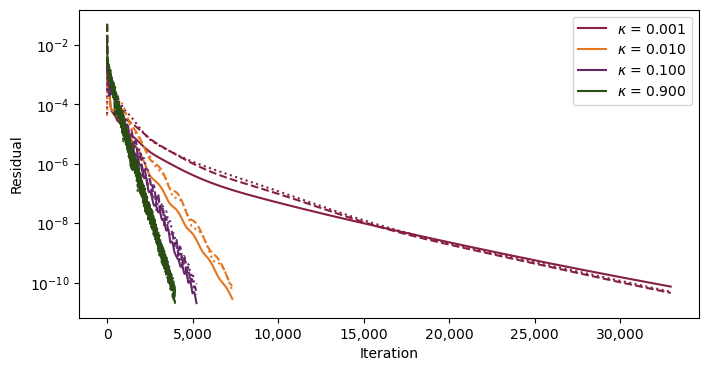

In [20]:
# pull out the 
CFL, RE, CX, IMAX = 0.9, 100, 0.01, 65
plt8df = paramdf[(paramdf.imms == 0) & (paramdf.cfl == CFL) & (paramdf.isgs == 1) &
    (paramdf.re == RE) & (paramdf.imax == IMAX) & (paramdf.cx == CX)]
plt8df = plt8df.sort_values(by='kappa', ascending=True)

# iterate through each 
fig, ax = plt.subplots(1, 1, figsize=(8,4))

# iterate through each file
for i, file in enumerate(plt8df.file.values):
    # read the consumption history
    hist = read_convergence_history(os.path.join(basepath, file, "history.dat"))

    # plot the history
    label = r"$\kappa$ = " + "{:.3f}".format(plt8df.iloc[i,6])
    ax.plot(hist.iteration, hist.resp, linestyle="solid", color=colors[i], label=label)
    ax.plot(hist.iteration, hist.resu, linestyle="dashed", color=colors[i])
    ax.plot(hist.iteration, hist.resv, linestyle="dotted", color=colors[i])

# format the axes
ax.set_xlabel("Iteration")
ax.set_ylabel("Residual")
ax.set_yscale('log')
ax.legend()
ax.get_xaxis().set_major_formatter(FuncFormatter(lambda x, p: "{:,.0f}".format(x)))

plt.savefig("../figs/kappa-convergence-comparison.png", dpi=600, bbox_inches='tight')
plt.show()    

## Instruction item 9. Effect of $C^{(4)}$ on DE

Effects of C(4) on the MMS solution: plot DE of pressure versus x location (0<x<0.01
m) at y near, but not at, 0.05 m (top of cavity). Refer to the plot in the lecture notes for an
example.

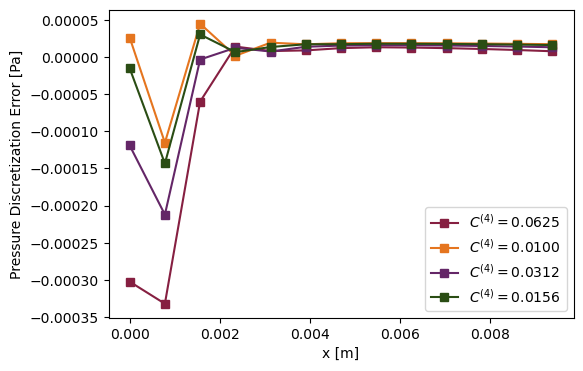

In [22]:
# get the relevant runs with the appropriate files
CFL, RE, KAPPA, IMAX = 0.9, 100, 0.1, 65
plt9df = paramdf[(paramdf.imms == 1) & (paramdf.kappa == KAPPA) & (paramdf.isgs == 1) &
    (paramdf.re == RE) & (paramdf.imax == IMAX)]
plt9df = plt9df.sort_values(by='kappa', ascending=True)

# intialize the plot
fig, ax = plt.subplots(1, 1, figsize=(6, 4))

# iterate through each of the rows
for i, file in enumerate(plt9df.file.values):
    # read in the data
    res = read_solution(os.path.join(basepath, file, "cavity.dat"))
    nx, ny = read_soln_size(os.path.join(basepath, file, "cavity.dat"))
    cx = plt9df.iloc[i, 7]

    # get the x, y as vectors only
    xv = res.x.values
    yv = res.y.values

    # get the y-index and the x-index of where to plot
    ix = np.unravel_index(np.where(xv > 0.01)[0][0], (nx, ny))[0]
    iy = ny - int(0.02 * ny) # get 5% down from the top
    
    # create a grid from the result values
    x = xv.reshape((nx, ny))
    y = yv.reshape((nx, ny))
    dep = res.dep.values.reshape((nx, ny))

    # slice the arrays at teh relevant locations
    xslc = x[:ix, iy]
    depslc = dep[:ix, iy]

    # plot the results
    label = r"$C^{(4)} = $" + f"{cx:.4f}"
    ax.plot(xslc, depslc, label=label, color=colors[i], marker='s')

# format the plot
ax.legend()
ax.set_ylabel("Pressure Discretization Error [Pa]")
ax.set_xlabel("x [m]")

# save and show the plot
plt.savefig("../figs/c4-de-comparison.png", dpi=600, bbox_inches='tight')
plt.show()

## Instruction item 10. Comparison against Literature

Comparison with literature, for example u or v velocity profile along the centerline of
the cavity and compare it with the results from the papers.

Note to self: compare against $\mathrm{Re} = 1,000$, as the papers have the most overlap for that. Compare with the following:
* Table VI, Erturk et al.
* Table 1, Ghia et al.
* Table 20, Marachi et al.
* Figure 12, Shankar and Deshpande